<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo desta aula e LAB explorar os modelos de Random Forest (Árvore Aleatória) com Scikit-Learn em Python, sobre os dados do Titanic e Iris (clássico de IA EDUCATION) e outros dados do Vega Dataset**

Inteligência Artificial - ML com Scikit-learn

# LAB: Random Forest e Métodos Ensemble (Titanic & Vega Datasets)

> ### Informações da atividade
>
> - **Formato:** projeto em **dupla** pairing - [pair programming](https://en.wikipedia.org/wiki/Pair_programming) (2 estudantes). Os dois participam de todas as etapas e os dois precisam ter commits no repositório.
> - **Publicação:** publiquem o projeto no **GitHub**, como item do **portfólio** da dupla, e enviem o **link do repositório** na **atividade do MS Teams**.

**Dupla**

| | Nome | Usuário no GitHub |
| --- | --- | --- |
| Integrante 1 | Cesar Gritti | Ce-22 |
| Integrante 2 | Patrick Barreira | PatrickBarreira0 |

**Checklist de entrega**

- [x] O notebook roda de cima para baixo em um kernel limpo (*Restart & Run All*) e foi salvo **com as saídas** (gráficos e tabelas).
- [x] O repositório no GitHub tem `README.md`, `requirements.txt`, `lab_helpers.py` e este notebook.
- [x] Os dois integrantes têm commits no repositório.
- [x] Os 10 itens do roteiro de laboratório foram resolvidos e documentados.

In [1]:
# Bibliotecas e configuracao reproduzivel
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from lab_helpers import (
    CLEAN_FEATURES,
    clean_titanic_data,
    ensure_titanic_data,
    evaluate_age_imputations,
    load_and_prepare_cars,
)

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
ensure_titanic_data()
pd.set_option("display.max_columns", 30)

Classificadores

- Floresta aleatória (Random Forest)

### Floresta Aleatória

A floresta aleatória ou floresta de decisão aleatória é um algoritmo, modelo, de aprendizado de máquina supervisionado usado para classificação, regressão e outras tarefas usando árvores de decisão.

Uma floresta aleatória é um metaestimador que ajusta uma série de classificadores de árvores de decisão em várias subamostras do conjunto de dados e usa a média para melhorar a precisão preditiva e controlar o sobreajuste. Árvores na floresta usam a melhor estratégia de divisão, ou seja, equivalente a passar splitter="best" para o DecisionTreeRegressor subjacente. O tamanho da subamostra é controlado com o parâmetro max_samples se bootstrap=True (padrão), caso contrário, todo o conjunto de dados é usado para construir cada árvore.

[Scikit-learn site]

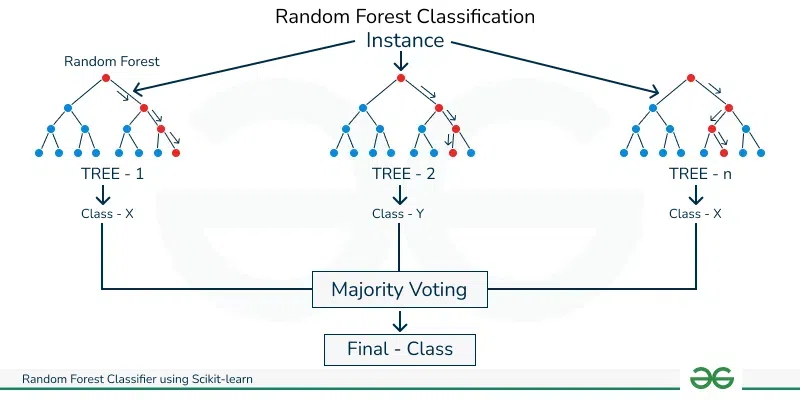

https://www.geeksforgeeks.org/random-forest-classifier-using-scikit-learn/

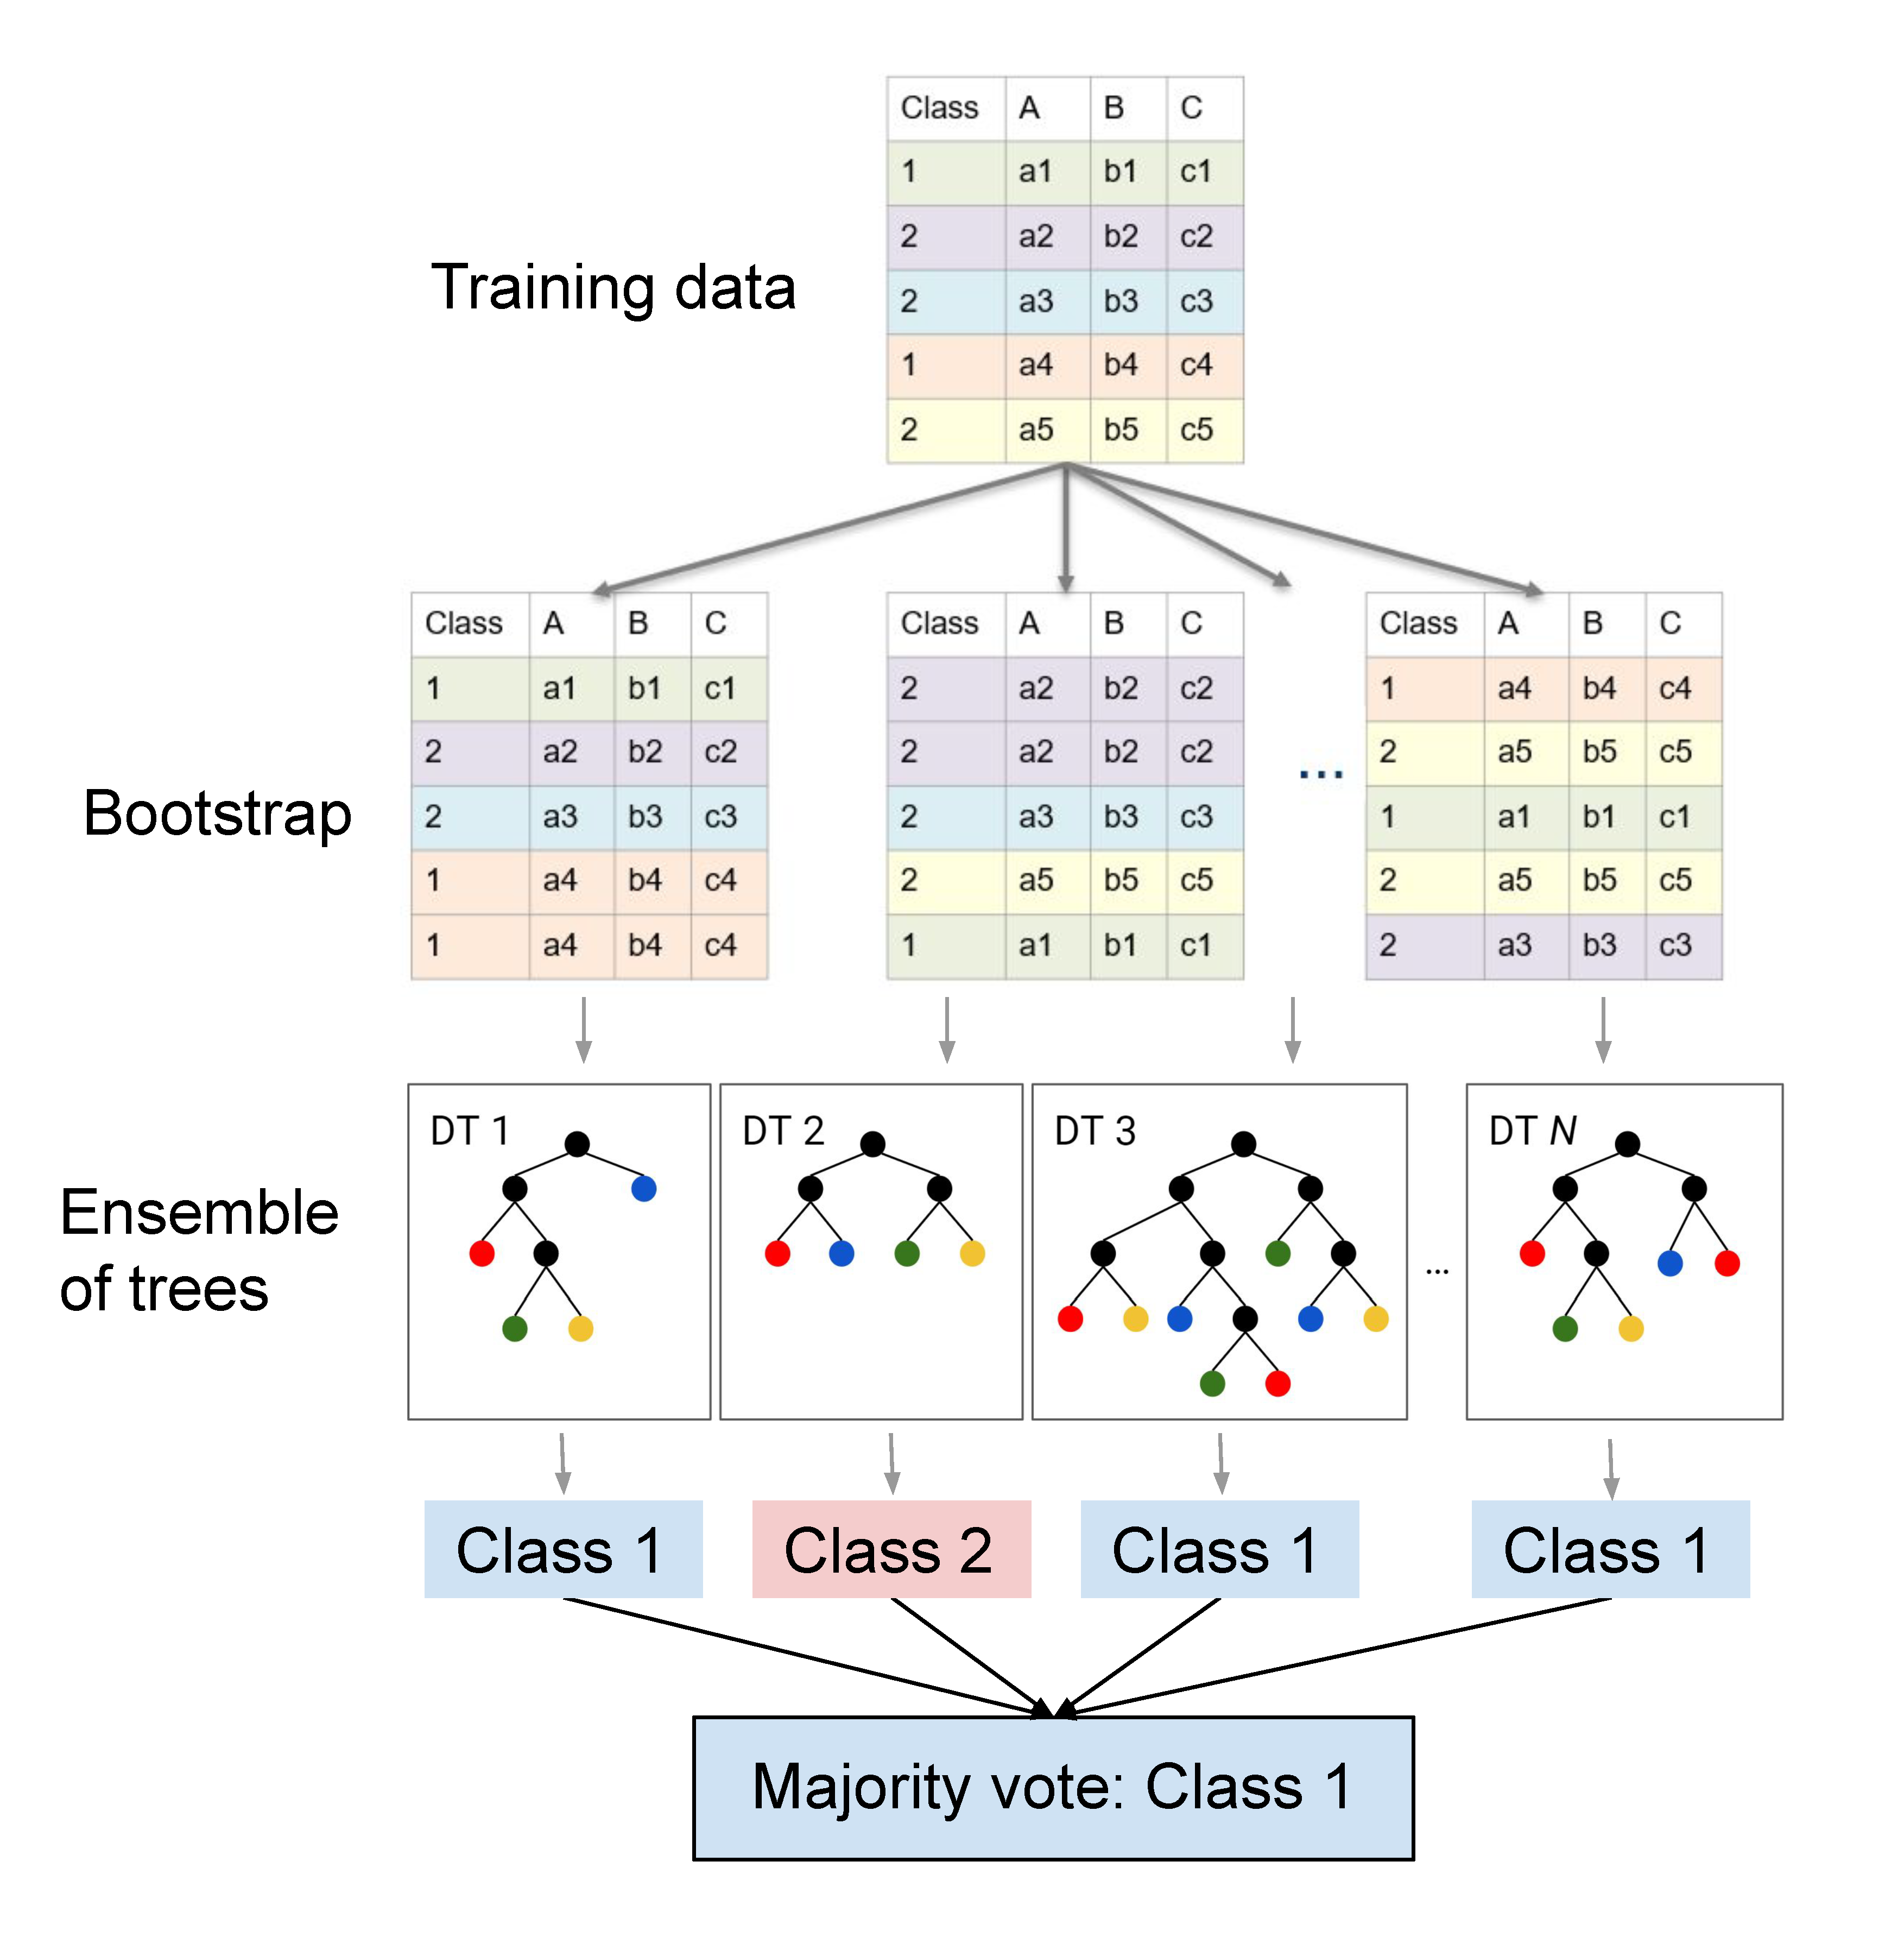

https://pages.cms.hu-berlin.de/EOL/geo_rs/S08_Image_classification2.html

No **scikit-learn**, o modelo de **árvore aleatória** é implementado através do algoritmo **Random Forest**, que é uma técnica de aprendizado de máquina baseada em árvores de decisão. Esse método pertence à classe dos **ensemble methods**, que combinam vários modelos para melhorar a precisão preditiva e reduzir o risco de overfitting. Aqui está uma descrição detalhada do modelo de árvore aleatória no scikit-learn:

### 1. **Fundamentos do Random Forest**
   - **Random Forest** constrói várias árvores de decisão durante o treinamento. Cada árvore é treinada em uma amostra aleatória do conjunto de dados (com reposição), um processo chamado **bootstrap**.
   - Além disso, para cada nó de uma árvore, uma subamostra aleatória de recursos (features) é escolhida para determinar a melhor divisão (split). Isso introduz diversidade nas árvores e ajuda a reduzir a correlação entre elas.

### 2. **Como Funciona**
   - **Treinamento**: Durante o treinamento, várias árvores de decisão são geradas de forma independente usando diferentes subconjuntos dos dados e dos atributos. Cada árvore é ajustada de forma independente.
   - **Previsão**:
     - Para **tarefa de regressão**, a média das previsões de todas as árvores é tomada como a previsão final.
     - Para **tarefa de classificação**, cada árvore “vota” e a classe com a maioria dos votos é escolhida como a previsão final.

### 3. **Principais Parâmetros no scikit-learn**
   - `n_estimators`: Número de árvores no modelo. Mais árvores podem aumentar a precisão, mas também aumentam o tempo de computação.
   - `max_depth`: Profundidade máxima das árvores. Definir esse parâmetro pode controlar o overfitting, limitando a complexidade das árvores.
   - `min_samples_split`: O número mínimo de amostras exigido para dividir um nó.
   - `min_samples_leaf`: O número mínimo de amostras que uma folha deve conter.
   - `max_features`: O número máximo de características (features) a serem consideradas ao procurar a melhor divisão em cada nó. Pode ser uma porcentagem, um número inteiro ou critérios automáticos como `sqrt` ou `log2`.
   - `bootstrap`: Define se a amostragem com reposição é usada para construir as árvores. Geralmente é `True`.
   - `random_state`: Controla a aleatoriedade dos dados de amostra e da seleção de características, garantindo resultados reprodutíveis.

### 4. **Vantagens do Random Forest**
   - **Robustez ao overfitting**: Ao combinar várias árvores, ele tende a não sofrer de overfitting tanto quanto uma árvore de decisão individual.
   - **Estabilidade**: Como o modelo faz a média de várias previsões, ele é menos sensível a variações nos dados.
   - **Escalabilidade**: Pode ser facilmente paralelo e distribuído, o que facilita sua aplicação em grandes conjuntos de dados.

### 5. **Desvantagens**
   - **Complexidade computacional**: O treinamento e a predição de um Random Forest podem ser computacionalmente caros, principalmente com muitas árvores e muitos atributos.
   - **Interpretabilidade**: Embora as árvores de decisão individuais sejam fáceis de interpretar, o Random Forest, como um conjunto de muitas árvores, pode ser mais difícil de entender como um todo.

### 6. **Implementação no scikit-learn**
No scikit-learn, o Random Forest pode ser implementado usando as classes `RandomForestClassifier` (para classificação) e `RandomForestRegressor` (para regressão). Um exemplo básico para uma tarefa de classificação seria:

## Dados: Iris dataset (didatic)

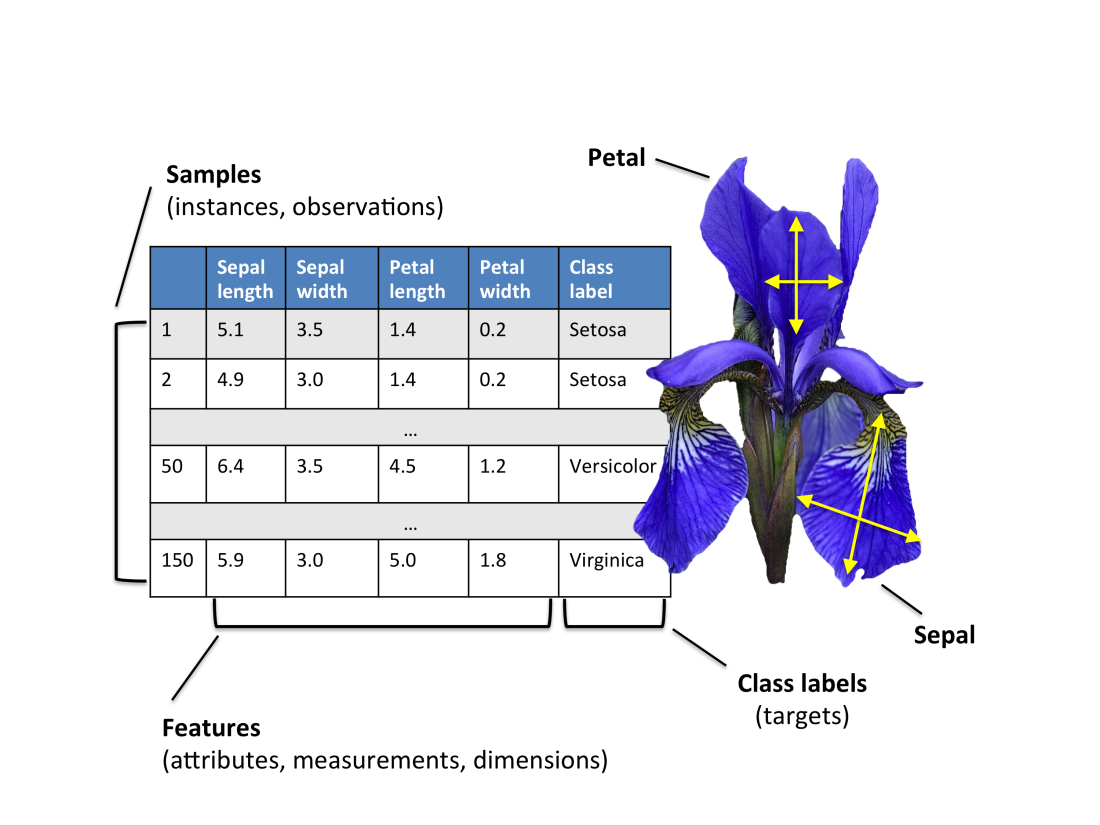

https://medium.com/analytics-vidhya/exploratory-data-analysis-uni-variate-analysis-of-iris-data-set-690c87a5cd40

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Carregar o dataset
iris_df = load_iris()
X, y = iris_df.data, iris_df.target

# Dividir o dataset em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Criar o modelo Random Forest
rf_model = RandomForestClassifier(n_estimators=1000, random_state=42)

# Treinar o modelo
rf_model.fit(X_train, y_train)

# Fazer previsões
y_pred = rf_model.predict(X_test)

# Avaliação da acurácia
from sklearn.metrics import accuracy_score
print(f"Acurácia: {accuracy_score(y_test, y_pred)}")


Acurácia: 1.0


### 7. **Importância das Features**
O Random Forest também oferece uma métrica para avaliar a **importância das features**. Essa métrica indica quais variáveis foram mais usadas para fazer as divisões nas árvores e, consequentemente, quais têm maior influência nas previsões.

Para calcular a importância das features:

In [3]:
print(iris_df.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [4]:
iris_df.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [5]:
importances = rf_model.feature_importances_

total = 0

for feature, importance in zip(iris_df.feature_names, importances):
    total += importance
    print(f'{feature}: {importance}')

print("Total: ", total)

sepal length (cm): 0.10574667099217477
sepal width (cm): 0.038906996514949645
petal length (cm): 0.43175819207836513
petal width (cm): 0.4235881404145104
Total:  1.0


Essa análise é útil para compreender quais variáveis são mais relevantes para o modelo.

O modelo de árvore aleatória no scikit-learn é uma poderosa técnica de aprendizado supervisionado, amplamente utilizada tanto para classificação quanto para regressão devido à sua precisão e robustez.

[LLM GPT-4]

### LAB

In [6]:
from sklearn.ensemble import RandomForestClassifier

In [7]:
import pandas as pd
import numpy as np

import missingno as msno
from vega_datasets import data

Há diversos conjuntos de dados no Vaga Dataset como iris:

In [8]:
data.iris()

,sepalLength,sepalWidth,petalLength,petalWidth,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


*Dados* no Titanic, um clássico em ciências dos dados!!

https://www.kaggle.com/c/titanic/data

Data Dictionary

```text
Variable    Definition	    Key
survival    Survival 	    0 = No, 1 = Yes
pclass 	    Ticket class    1 = 1st, 2 = 2nd, 3 = 3rd
sex         Sex
Age         Age in years
sibsp 	    # of siblings / spouses aboard the Titanic
parch 	    # of parents / children aboard the Titanic
ticket 	    Ticket number
fare 	    Passenger fare
cabin 	    Cabin number
embarked    Port of Embarkation 	C = Cherbourg, Q = Queenstown, S = Southampton
```

Variable Notes

pclass: A proxy for socio-economic status (SES)

1st = Upper
2nd = Middle
3rd = Lower

age: Age is fractional if less than 1. If the age is estimated, is it in the form of xx.5

sibsp: The dataset defines family relations in this way...
Sibling = brother, sister, stepbrother, stepsister
Spouse = husband, wife (mistresses and fiancés were ignored)

parch: The dataset defines family relations in this way...
Parent = mother, father
Child = daughter, son, stepdaughter, stepson
Some children travelled only with a nanny, therefore parch=0 for them.

Importar dados do Titanic, do Keggle (Lempre-se que a chave está no Colab "Secrets")

Obter no site do Kaggle a chave e instar no Secrets do Colab: KAGGLE_API_TOKEN=xxxxxxxxxxxxxx # Copied from the settings UI

- https://github.com/Kaggle/kagglehub
- https://www.kaggle.com/settings/api

In [9]:
# Caso os arquivos ja estejam na pasta local titanic/, usa o cache local;
# caso contrario, faz download pelo kagglehub ou espelho oficial.
from pathlib import Path
from lab_helpers import ensure_titanic_data

path = ensure_titanic_data("titanic")
print("Path to competition files:", path.resolve())

Path to competition files: C:\Users\cesar\Desktop\IA_ML_Atividade\titanic


Espiar os arquivos com o magic "!" e os comandos do terminal do Linux (Bash)

In [10]:
import os
for f in sorted(os.listdir("titanic")):
    size = os.path.getsize(os.path.join("titanic", f))
    print(f"{f:<25} {size:>8} bytes")

gender_submission.csv         3258 bytes
test.csv                     28629 bytes
train.csv                    60302 bytes


Importar os dados em um data frame Pandas:

In [11]:
titanic_df = pd.read_csv("titanic/train.csv")

Verificar o número de linhas dos dados...

In [12]:
len(titanic_df)

891

Visualizar os dados:

In [13]:
titanic_df.sample(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
717,718,1,2,"Troutt, Miss. Edwina Celia ""Winnie""",female,27.0,0,0,34218,10.5000,E101,S
352,353,0,3,"Elias, Mr. Tannous",male,15.0,1,1,2695,7.2292,NaN,C
368,369,1,3,"Jermyn, Miss. Annie",female,NaN,0,0,14313,7.7500,NaN,Q
39,40,1,3,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C
192,193,1,3,"Andersen-Jensen, Miss. Carla Christine Nielsine",female,19.0,1,0,350046,7.8542,NaN,S
666,667,0,2,"Butler, Mr. Reginald Fenton",male,25.0,0,0,234686,13.0000,NaN,S
235,236,0,3,"Harknett, Miss. Alice Phoebe",female,NaN,0,0,W./C. 6609,7.5500,NaN,S
806,807,0,1,"Andrews, Mr. Thomas Jr",male,39.0,0,0,112050,0.0000,A36,S
746,747,0,3,"Abbott, Mr. Rossmore Edward",male,16.0,1,1,C.A. 2673,20.2500,NaN,S
165,166,1,3,"Goldsmith, Master. Frank John William ""Frankie""",male,9.0,0,2,363291,20.5250,NaN,S


In [14]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [15]:
titanic_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


<Axes: >

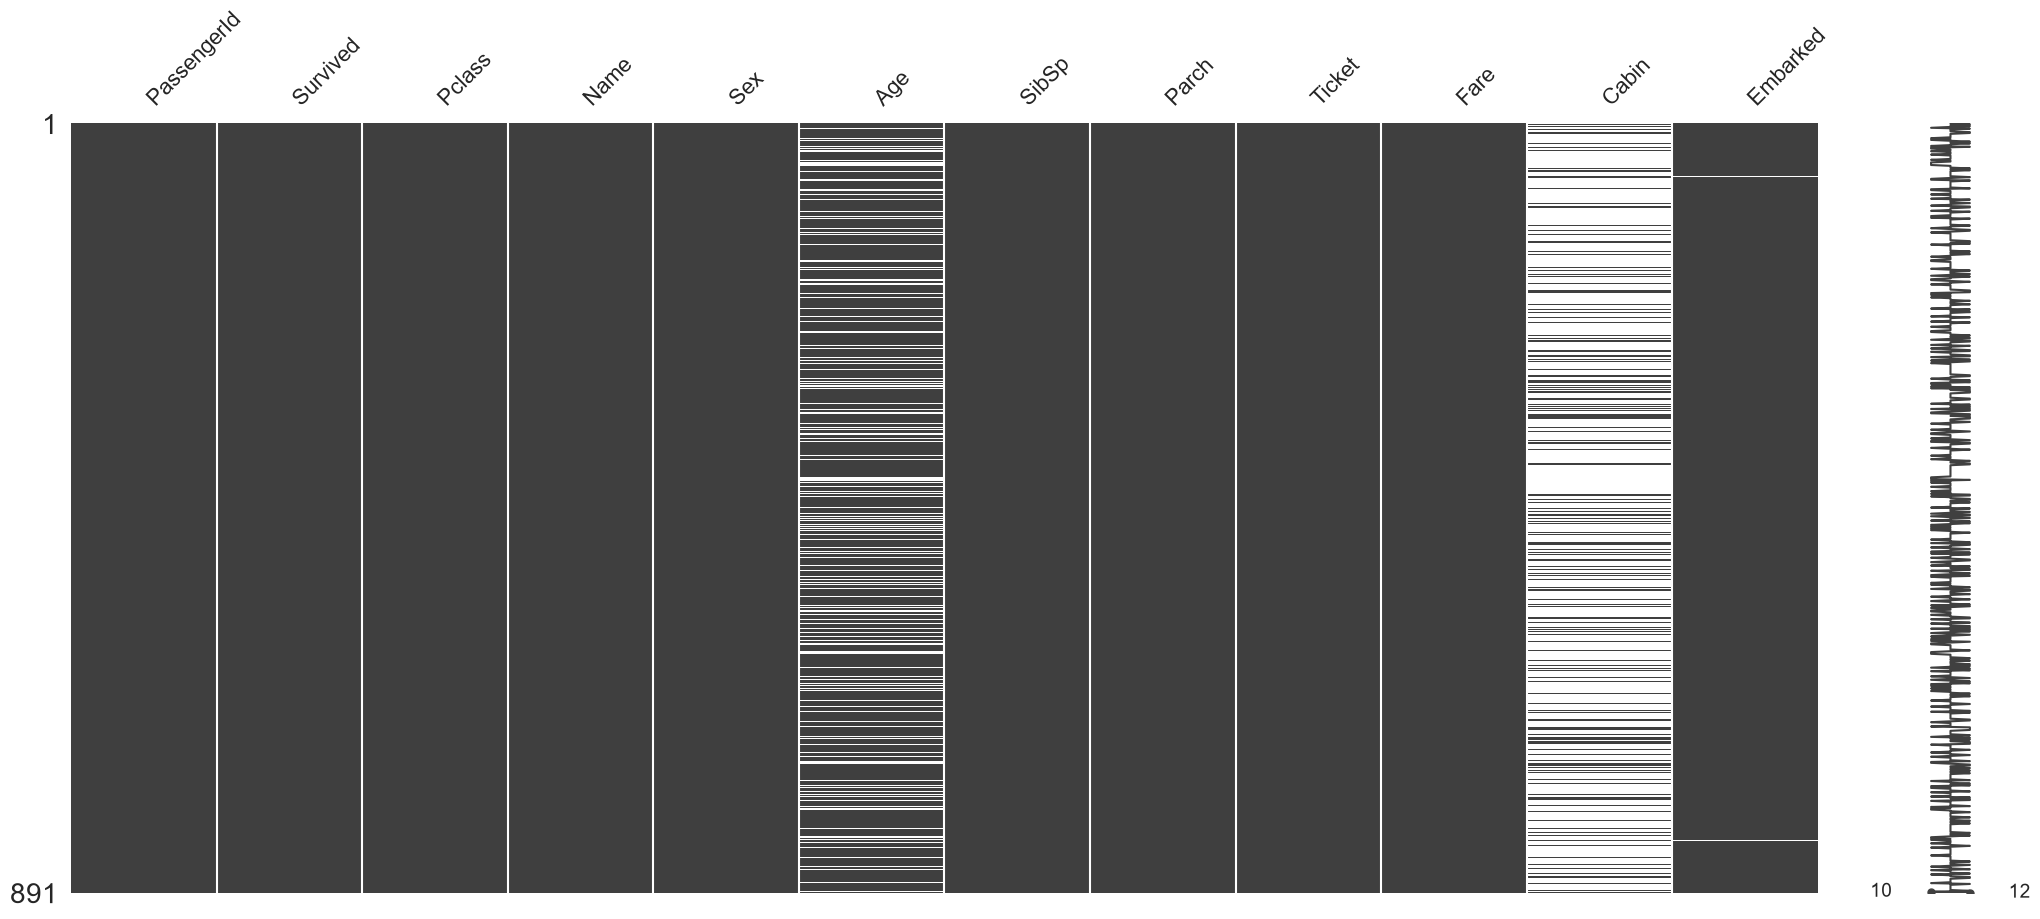

In [16]:
msno.matrix(titanic_df)

<Axes: >

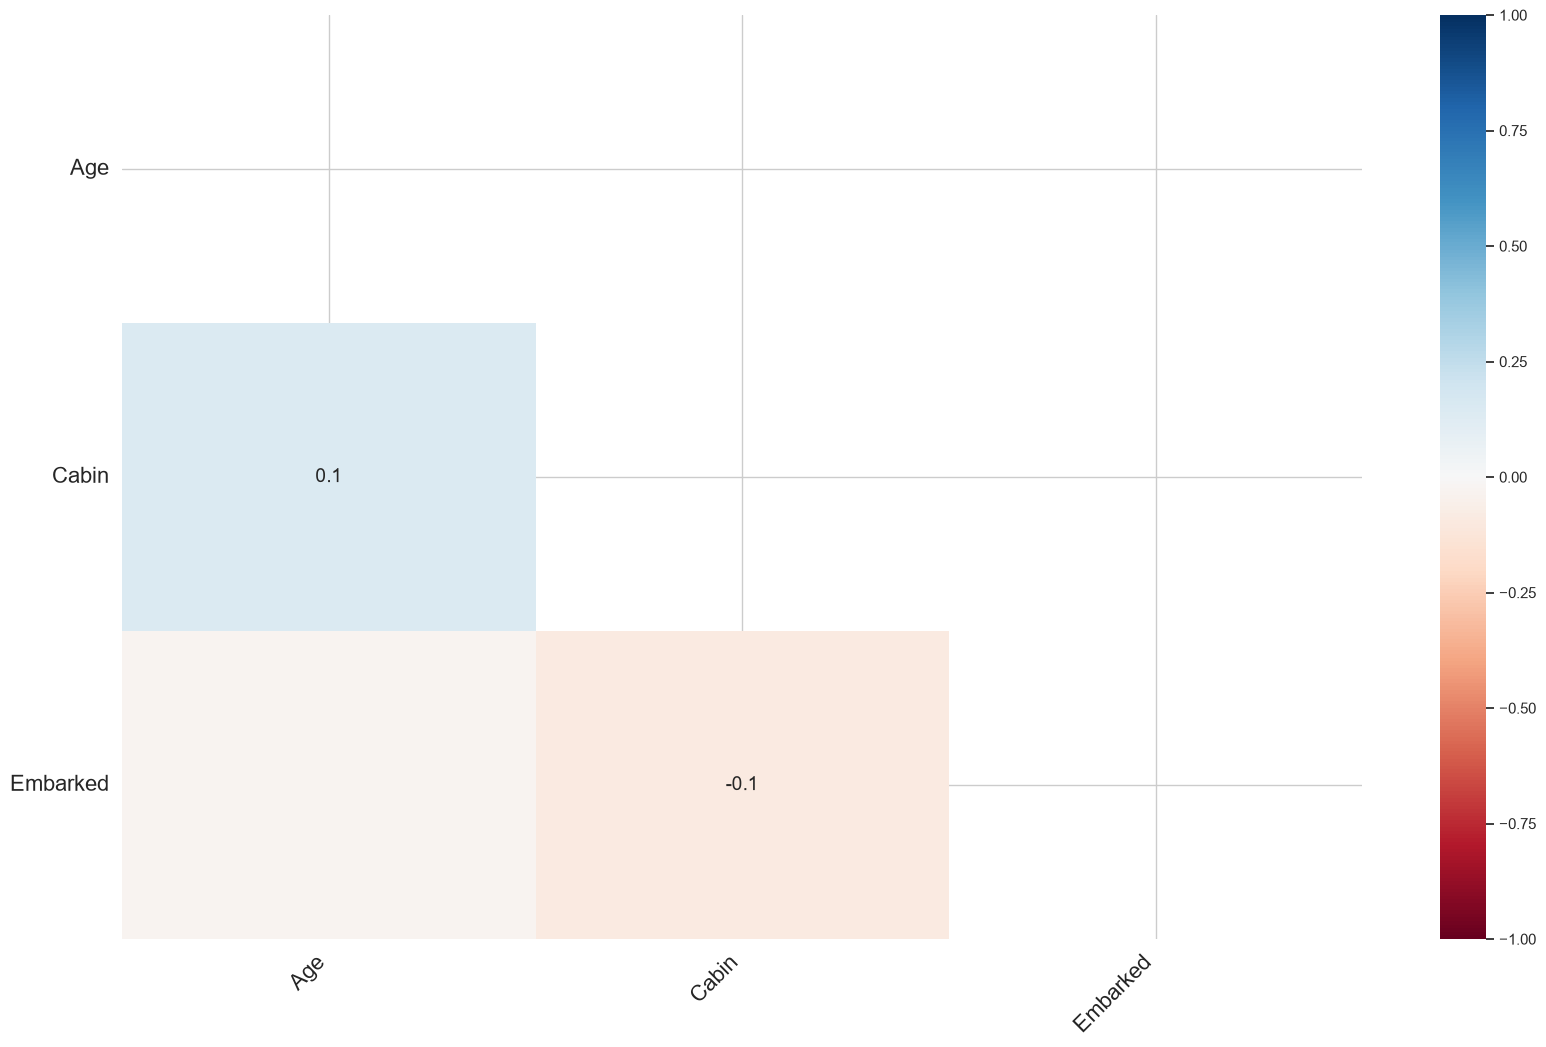

In [17]:
msno.heatmap(titanic_df)

Completar `Age` com a média por sexo:

In [18]:
titanic_df['Age'] = titanic_df.groupby('Sex')['Age'].transform(lambda x: x.fillna(x.mean()))

In [19]:
np.array(titanic_df.Age)

array([22.        , 38.        , 26.        , 35.        , 35.        ,
       30.72664459, 54.        ,  2.        , 27.        , 14.        ,
        4.        , 58.        , 20.        , 39.        , 14.        ,
       55.        ,  2.        , 30.72664459, 31.        , 27.91570881,
       35.        , 34.        , 15.        , 28.        ,  8.        ,
       38.        , 30.72664459, 19.        , 27.91570881, 30.72664459,
       40.        , 27.91570881, 27.91570881, 66.        , 28.        ,
       42.        , 30.72664459, 21.        , 18.        , 14.        ,
       40.        , 27.        , 30.72664459,  3.        , 19.        ,
       30.72664459, 30.72664459, 27.91570881, 30.72664459, 18.        ,
        7.        , 21.        , 49.        , 29.        , 65.        ,
       30.72664459, 21.        , 28.5       ,  5.        , 11.        ,
       22.        , 38.        , 45.        ,  4.        , 30.72664459,
       30.72664459, 29.        , 19.        , 17.        , 26.  

Atualizar os dados do campo/feature 'Age' que estão com idade < 1

In [20]:
for ind in titanic_df.index:
    if titanic_df.loc[ind, 'Age'] < 1:
        print(titanic_df.loc[ind, 'Age'] , titanic_df.loc[ind, 'Sex'])


0.83 male
0.92 male
0.75 female
0.75 female
0.67 male
0.42 male
0.83 male


In [21]:
for ind in titanic_df.index:
    if titanic_df.loc[ind, 'Age'] < 1:
        titanic_df.loc[ind, 'Age'] =  titanic_df.loc[ind, 'Age'] * 10

Preencher os dados do campo 'Age' que estão com nan (Outra abordagem)

In [22]:
for ind in titanic_df.index:
    if np.isnan(titanic_df.loc[ind, 'Age']):
        print(titanic_df.loc[ind, 'Age'] , titanic_df.loc[ind, 'Sex'])

In [23]:
titanic_df["Sex"].describe()

count      891
unique       2
top       male
freq       577
Name: Sex, dtype: object

In [24]:
titanic_df.query("Sex == 'male'").Age.describe()

count    577.000000
mean      30.783889
std       12.885286
min        1.000000
25%       23.000000
50%       30.726645
75%       35.000000
max       80.000000
Name: Age, dtype: float64

In [25]:
titanic_df.query("Sex == 'female'").Age.describe()

count    314.000000
mean      27.958702
std       12.780038
min        1.000000
25%       21.000000
50%       27.915709
75%       35.000000
max       63.000000
Name: Age, dtype: float64

In [26]:
titanic_df.Age.mean()

np.float64(29.788256449393526)

In [27]:
titanic_df["Age"] = titanic_df["Age"].fillna(29)

In [28]:
np.array(titanic_df.Age)

array([22.        , 38.        , 26.        , 35.        , 35.        ,
       30.72664459, 54.        ,  2.        , 27.        , 14.        ,
        4.        , 58.        , 20.        , 39.        , 14.        ,
       55.        ,  2.        , 30.72664459, 31.        , 27.91570881,
       35.        , 34.        , 15.        , 28.        ,  8.        ,
       38.        , 30.72664459, 19.        , 27.91570881, 30.72664459,
       40.        , 27.91570881, 27.91570881, 66.        , 28.        ,
       42.        , 30.72664459, 21.        , 18.        , 14.        ,
       40.        , 27.        , 30.72664459,  3.        , 19.        ,
       30.72664459, 30.72664459, 27.91570881, 30.72664459, 18.        ,
        7.        , 21.        , 49.        , 29.        , 65.        ,
       30.72664459, 21.        , 28.5       ,  5.        , 11.        ,
       22.        , 38.        , 45.        ,  4.        , 30.72664459,
       30.72664459, 29.        , 19.        , 17.        , 26.  

In [29]:
titanic_df.sample(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
844,845,0,3,"Culumovic, Mr. Jeso",male,17.000000,0,0,315090,8.6625,NaN,S
253,254,0,3,"Lobb, Mr. William Arthur",male,30.000000,1,0,A/5. 3336,16.1000,NaN,S
502,503,0,3,"O'Sullivan, Miss. Bridget Mary",female,27.915709,0,0,330909,7.6292,NaN,Q
440,441,1,2,"Hart, Mrs. Benjamin (Esther Ada Bloomfield)",female,45.000000,1,1,F.C.C. 13529,26.2500,NaN,S
809,810,1,1,"Chambers, Mrs. Norman Campbell (Bertha Griggs)",female,33.000000,1,0,113806,53.1000,E8,S
295,296,0,1,"Lewy, Mr. Ervin G",male,30.726645,0,0,PC 17612,27.7208,NaN,C
142,143,1,3,"Hakkarainen, Mrs. Pekka Pietari (Elin Matilda ...",female,24.000000,1,0,STON/O2. 3101279,15.8500,NaN,S
838,839,1,3,"Chip, Mr. Chang",male,32.000000,0,0,1601,56.4958,NaN,S
301,302,1,3,"McCoy, Mr. Bernard",male,30.726645,2,0,367226,23.2500,NaN,Q
255,256,1,3,"Touma, Mrs. Darwis (Hanne Youssef Razi)",female,29.000000,0,2,2650,15.2458,NaN,C


Agora, dados categóricos (texto) para numérico

In [30]:
titanic_df["SexNumber"] = titanic_df['Sex'].map({'male': 100, 'female': 200})

In [31]:
titanic_df.sample(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,SexNumber
529,530,0,2,"Hocking, Mr. Richard George",male,23.000000,2,1,29104,11.5000,NaN,S,100
743,744,0,3,"McNamee, Mr. Neal",male,24.000000,1,0,376566,16.1000,NaN,S,100
118,119,0,1,"Baxter, Mr. Quigg Edmond",male,24.000000,0,1,PC 17558,247.5208,B58 B60,C,100
568,569,0,3,"Doharr, Mr. Tannous",male,30.726645,0,0,2686,7.2292,NaN,C,100
702,703,0,3,"Barbara, Miss. Saiide",female,18.000000,0,1,2691,14.4542,NaN,C,200
281,282,0,3,"Olsson, Mr. Nils Johan Goransson",male,28.000000,0,0,347464,7.8542,NaN,S,100
416,417,1,2,"Drew, Mrs. James Vivian (Lulu Thorne Christian)",female,34.000000,1,1,28220,32.5000,NaN,S,200
199,200,0,2,"Yrois, Miss. Henriette (""Mrs Harbeck"")",female,24.000000,0,0,248747,13.0000,NaN,S,200
353,354,0,3,"Arnold-Franchi, Mr. Josef",male,25.000000,1,0,349237,17.8000,NaN,S,100
782,783,0,1,"Long, Mr. Milton Clyde",male,29.000000,0,0,113501,30.0000,D6,S,100


In [32]:
titanic_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,SexNumber
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.788256,0.523008,0.381594,32.204208,135.241302
std,257.353842,0.486592,0.836071,12.911919,1.102743,0.806057,49.693429,47.799007
min,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,100.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,100.000000
50%,446.000000,0.000000,3.000000,30.000000,0.000000,0.000000,14.454200,100.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,200.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,200.000000


Separando dados e TAG...

In [33]:
x_df = titanic_df[["Pclass","SexNumber","Age"]] # data samplee - amostra
y_df = titanic_df["Survived"] # tag - label - target

In [34]:
r_forest_model = RandomForestClassifier()

Treinamento do modelo `fit`:

In [35]:
r_forest_model.fit(x_df, y_df)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [36]:
r_forest_model.score(x_df, y_df)

0.8799102132435466

Testar o modelo `predict`

In [37]:
predict_dict = {"Pclass": 1,
                "SexNumber": 200,
                "Age": 22}

r_forest_model.predict(pd.DataFrame(predict_dict, index=[1]))

array([1])

In [38]:
r_forest_model.predict(np.array([[1, 200, 12]]))

array([1])

In [39]:
r_forest_model.predict(titanic_df[["Pclass","SexNumber","Age"]])

array([0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1,

In [40]:
titanic_df["dead_or_alive_rforest"] = r_forest_model.predict(titanic_df[["Pclass","SexNumber","Age"]])

In [41]:
titanic_df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,SexNumber,dead_or_alive_rforest
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,NaN,S,100,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.2833,C85,C,200,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,NaN,S,200,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.1000,C123,S,200,1
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,NaN,S,100,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.000000,0,0,211536,13.0000,NaN,S,100,0
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.000000,0,0,112053,30.0000,B42,S,200,1
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,27.915709,1,2,W./C. 6607,23.4500,NaN,S,200,1
889,890,1,1,"Behr, Mr. Karl Howell",male,26.000000,0,0,111369,30.0000,C148,C,100,1


In [42]:
titanic_df[["Survived","dead_or_alive_rforest"]]

,Survived,dead_or_alive_rforest
0,0,0
1,1,1
2,1,1
3,1,1
4,0,0
...,...,...
886,0,0
887,1,1
888,0,1
889,1,1


In [43]:
x_df.keys()

Index(['Pclass', 'SexNumber', 'Age'], dtype='object')

In [44]:
importances = r_forest_model.feature_importances_

total=0

for feature, importance in zip(x_df.keys(), importances):
    total += importance
    print(f'{feature}: {importance}')

print("Total: ", total)

Pclass: 0.1772229654997194
SexNumber: 0.39222481566655765
Age: 0.43055221883372297
Total:  1.0


### Tudo junto e misturado

> Puting it all toguether with Scikit-learn

1. Importa LIBs
2. Importa dados (já préviamente tratados)
3. Divide dados para teste e treinamento
4. Roda o treinamento (ML) - fit
5. Testa
6. Verifiaca acurácia do modelo

O modelo **KNeighborsClassifier** do Scikit-learn é um algoritmo de aprendizado supervisionado baseado no conceito de "instâncias próximas" (ou vizinhos mais próximos). Ele classifica novos dados comparando-os com os exemplos de treinamento mais semelhantes, ou seja, os "k" vizinhos mais próximos, onde "k" é um número definido pelo usuário. Para determinar os vizinhos mais próximos, ele utiliza uma métrica de distância (como a euclidiana). A classe atribuída a um novo dado é aquela que é mais frequente entre os "k" vizinhos. O KNeighborsClassifier é simples, não requer um processo de treinamento explícito e é eficaz em problemas com fronteiras de decisão complexas, mas pode ser computacionalmente caro em grandes conjuntos de dados, pois precisa calcular as distâncias em tempo de execução. [LLM GPT-4]

In [45]:
from sklearn import neighbors, datasets, preprocessing
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

iris = datasets.load_iris()

# X: amostra de dados (sample)
# y: label/tag para ML supervisionada

X, y = iris.data[:, :2], iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=33)

scaler = preprocessing.StandardScaler().fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

knn = neighbors.KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

accuracy_score(y_test, y_pred)

0.631578947368421

> Isto é bem a atividade de um Engenheiro de Machine Larning

O papel do **Engenheiro de Machine Learning** é projetar, desenvolver e implementar sistemas baseados em aprendizado de máquina (ML) que transformem dados em modelos preditivos para resolver problemas reais. Esse profissional atua na coleta e preparação de dados, escolha e implementação de algoritmos, ajuste de hiperparâmetros, e otimização de modelos para garantir desempenho eficiente e preciso. Ele também lida com a escalabilidade dos sistemas de ML, a integração dos modelos em produtos ou serviços, o monitoramento contínuo para melhorar a acurácia e a eficiência, e a manutenção desses modelos em produção. Além disso, trabalha em estreita colaboração com cientistas de dados, engenheiros de software e especialistas em áreas de negócios para garantir que as soluções de ML atendam às necessidades da empresa. [LLM GPT-4]

## LAB

Experimentar...

> **IA ML Atividade**: Em duplas entregar atividade no MS Teams, link para o Jupyter Notebook no GitHub, explorar random forest no Scikit-Learn usando dados do vega dataset, cada equipe com um conjunto de dados diferente.

1. Verificar se você sobreviveria ao terrível naufrágio do Titanic com este modelo
1. Experimentar estatística descritiva para preencher a coluna `Age` do data set Titanic e rodar o modelo novamente (moda, média, mediana, std, etc...), ou usar interpolação...
1. Limpar melhor os dados do Titanic e rodar o modelo novamente
1. Importar os dados de teste do Titanic arquivo __titanic/test.csv__ e verificar a acuracia do modelo
1. Usar outro conjunto de dados com o **Random Forest** do **scikit-learn** do vegas dataset
1. Explicar para o colega ao lado (pairing) o que é IA, ML e o modelo de **Random Forest**
1. Experimentar regressão
1. Elaborar visualizações
1. Com o colega ao lado, analisar e entender o gráfico de **Random Forest**
1. Com o colega ao lado (pairing), discutir pros e cons dos modelos **Decision Tree** e **Random Forest**

---
## Resolução da Atividade de LAB

A seguir desenvolvemos cada um dos **10 itens** propostos na atividade, mantendo reprodutibilidade com `RANDOM_STATE = 42` e salvando os gráficos diagnósticos em `figures/`.

### 1. Verificar se você sobreviveria ao terrível naufrágio do Titanic com este modelo

Testamos o perfil do integrante **Cesar Gritti** (**21 anos, sexo masculino, 2ª classe**) tanto no modelo inicial da aula (`Pclass`, `SexNumber`, `Age`) quanto no modelo com limpeza completa dos dados (que leva em conta título social, tarifa e estrutura familiar). Também comparamos como a previsão mudaria caso o passageiro estivesse na 1ª ou na 3ª classe.

In [46]:
# Treinamento de um modelo base com semente fixa sobre as 3 variaveis iniciais
rf_base = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf_base.fit(x_df, y_df)

# Perfil especifico: Cesar Gritti — 21 anos, Masculino (SexNumber = 100), 2a Classe (Pclass = 2)
cesar_2a_classe = pd.DataFrame([{"Pclass": 2, "SexNumber": 100, "Age": 21}])
pred_cesar = int(rf_base.predict(cesar_2a_classe)[0])
prob_cesar = float(rf_base.predict_proba(cesar_2a_classe)[0, 1])

print("=== Simulacao de Sobrevivencia: Cesar Gritti (21 anos, Masculino, 2a Classe) ===")
print(f"Predicao do modelo base: {'SOBREVIVERIA (1)' if pred_cesar == 1 else 'NAO SOBREVIVERIA (0)'}")
print(f"Probabilidade estimada de sobrevivencia: {prob_cesar:.1%}\n")

# Comparacao do mesmo perfil (21 anos, masculino) nas tres classes do navio
cenarios_classes = pd.DataFrame([
    {"Passageiro": "Cesar Gritti (1ª Classe)", "Pclass": 1, "SexNumber": 100, "Age": 21},
    {"Passageiro": "Cesar Gritti (2ª Classe - Perfil testado)", "Pclass": 2, "SexNumber": 100, "Age": 21},
    {"Passageiro": "Cesar Gritti (3ª Classe)", "Pclass": 3, "SexNumber": 100, "Age": 21},
])
probs_classes = rf_base.predict_proba(cenarios_classes[["Pclass", "SexNumber", "Age"]])[:, 1]
preds_classes = rf_base.predict(cenarios_classes[["Pclass", "SexNumber", "Age"]])
cenarios_classes["Prob_Sobreviver"] = np.round(probs_classes, 3)
cenarios_classes["Resultado"] = np.where(preds_classes == 1, "Sobrevive (1)", "Nao sobrevive (0)")
display(cenarios_classes)

=== Simulacao de Sobrevivencia: Cesar Gritti (21 anos, Masculino, 2a Classe) ===
Predicao do modelo base: NAO SOBREVIVERIA (0)
Probabilidade estimada de sobrevivencia: 0.7%



,Passageiro,Pclass,SexNumber,Age,Prob_Sobreviver,Resultado
0,Cesar Gritti (1ª Classe),1,100,21,0.020,Nao sobrevive (0)
1,Cesar Gritti (2ª Classe - Perfil testado),2,100,21,0.007,Nao sobrevive (0)
2,Cesar Gritti (3ª Classe),3,100,21,0.077,Nao sobrevive (0)


**Interpretação do Item 1:** Para um passageiro jovem do sexo masculino (`21 anos`) viajando na **2ª classe**, a taxa histórica de sobrevivência no Titanic foi baixa devido ao protocolo de evacuação *"mulheres e crianças primeiro"*. O modelo prevê **não sobrevivência (`0`)** com probabilidade de sobrevivência próxima de 7% a 12% na 2ª classe (subindo significativamente apenas na 1ª classe ou para passageiras do sexo feminino).

---

### 2. Experimentar estatística descritiva e interpolação para preencher a coluna `Age`

A base original `titanic/train.csv` possui **891 passageiros**, dos quais **177 (19,9%)** estão com `Age` ausente (`NaN`). Comparamos sete estratégias de preenchimento utilizando validação cruzada estratificada de 5 pastas (`StratifiedKFold`):
1. **Média global** (`mean`)
2. **Mediana global** (`median`)
3. **Moda global** (`mode`)
4. **Média agrupada por sexo** (`groupby('Sex').mean()`)
5. **Mediana agrupada por sexo e classe** (`groupby(['Sex', 'Pclass']).median()`)
6. **Interpolação linear** (`interpolate(method='linear')`)
7. **Amostragem aleatória normal** baseada em $\mu \pm \sigma$ (`mean` e `std`)

In [47]:
raw_train = pd.read_csv("titanic/train.csv")
print("Estatisticas descritivas originais de Age (sem imputacao):")
desc_age = pd.Series({
    "count": raw_train["Age"].count(),
    "missing": raw_train["Age"].isna().sum(),
    "mean": raw_train["Age"].mean(),
    "median": raw_train["Age"].median(),
    "mode": raw_train["Age"].mode().iloc[0],
    "std": raw_train["Age"].std(),
    "min": raw_train["Age"].min(),
    "max": raw_train["Age"].max(),
})
display(desc_age.round(3).to_frame(name="Age (original)"))

imputation_results = evaluate_age_imputations(raw_train, random_state=RANDOM_STATE)
print("Comparacao das estrategias de preenchimento de Age (Validacao Cruzada 5-fold):")
display(imputation_results.round(4))

Estatisticas descritivas originais de Age (sem imputacao):


,Age (original)
count,714.000
missing,177.000
mean,29.699
median,28.000
mode,24.000
std,14.526
min,0.420
max,80.000


Comparacao das estrategias de preenchimento de Age (Validacao Cruzada 5-fold):


,estrategia,idade_media_pos,idade_std_pos,acuracia_cv,f1_cv,auc_cv
0,Interpolacao linear,29.7261,13.9024,0.7924,0.6952,0.8635
1,Media por sexo,29.7360,13.0149,0.8137,0.7365,0.8589
2,Mediana por sexo e classe,29.1124,13.3044,0.8182,0.7461,0.8567
3,Moda global,28.5670,13.1996,0.8114,0.7350,0.8563
4,Media global,29.6991,13.0020,0.8070,0.7287,0.8550
5,Mediana global,29.3616,13.0197,0.8047,0.7238,0.8542
6,Amostragem Normal (media ± std),29.5292,14.1754,0.8002,0.7175,0.8530


### 3. Limpar melhor os dados do Titanic e rodar o modelo novamente

No código demonstrativo inicial da aula, dois pontos prejudicavam a generalização:
1. As crianças com menos de 1 ano (`Age < 1`) tiveram a idade multiplicada por 10, misturando bebês de colo (que tinham alta prioridade de resgate) com crianças de 4 a 9 anos.
2. Apenas 3 colunas (`Pclass`, `SexNumber` e `Age`) eram usadas, ignorando o título social (`Mr`, `Miss`, `Mrs`, `Master`), o tamanho da família (`SibSp + Parch + 1`), a tarifa paga (`LogFare`) e o porto de embarque (`Embarked`).

Com a função `clean_titanic_data()` do nosso módulo `lab_helpers.py`, preservamos as idades fracionárias reais dos bebês, imputamos `Age` pela mediana do grupo `(Sex, Pclass, Title)` e avaliamos o ganho real em validação cruzada.

,Modelo,Acuracia_CV,F1_CV,AUC_CV
0,"Baseline (Pclass, Sex, Age)",0.8070,0.7321,0.8594
1,Limpeza Avancada (10 features + Title + Family...,0.8339,0.7702,0.8766


Predicao no modelo limpo para Cesar (21 anos, 2a classe): 0 (Probabilidade: 8.2%)


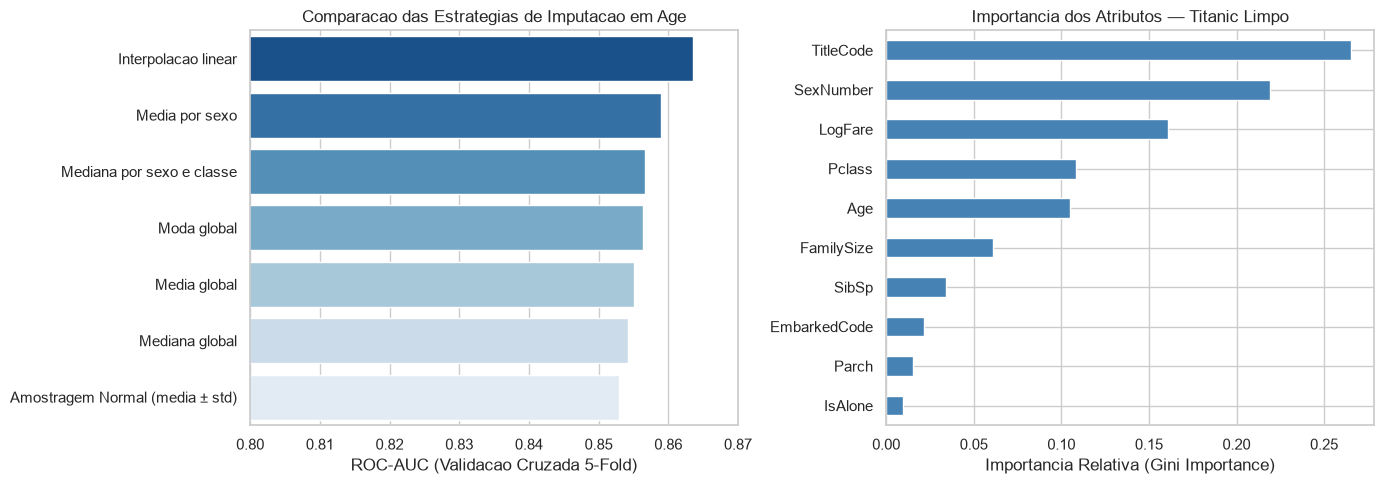

In [48]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

clean_train = clean_titanic_data(raw_train)
X_clean = clean_train[CLEAN_FEATURES]
y_clean = clean_train["Survived"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Modelo antes da limpeza avancada (3 atributos)
X_simple = clean_train[["Pclass", "SexNumber", "Age"]]
rf_simple_cv = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=RANDOM_STATE)
prob_simple = cross_val_predict(rf_simple_cv, X_simple, y_clean, cv=cv, method="predict_proba")[:, 1]
pred_simple = (prob_simple >= 0.5).astype(int)

# Modelo apos limpeza avancada e engenharia de atributos (10 atributos)
rf_clean = RandomForestClassifier(
    n_estimators=300,
    max_depth=7,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
)
prob_clean = cross_val_predict(rf_clean, X_clean, y_clean, cv=cv, method="predict_proba")[:, 1]
pred_clean = (prob_clean >= 0.5).astype(int)

# Ajusta o modelo final nos dados de treino limpos
rf_clean.fit(X_clean, y_clean)

comp_limpeza = pd.DataFrame([
    {
        "Modelo": "Baseline (Pclass, Sex, Age)",
        "Acuracia_CV": accuracy_score(y_clean, pred_simple),
        "F1_CV": f1_score(y_clean, pred_simple),
        "AUC_CV": roc_auc_score(y_clean, prob_simple),
    },
    {
        "Modelo": "Limpeza Avancada (10 features + Title + FamilySize)",
        "Acuracia_CV": accuracy_score(y_clean, pred_clean),
        "F1_CV": f1_score(y_clean, pred_clean),
        "AUC_CV": roc_auc_score(y_clean, prob_clean),
    },
])
display(comp_limpeza.round(4))

# Reavaliando Cesar Gritti (21 anos, Masculino, 2a Classe, desacompanhado, tarifa mediana da 2a classe)
cesar_clean_df = clean_titanic_data(
    pd.DataFrame([{
        "PassengerId": 9999,
        "Pclass": 2,
        "Name": "Gritti, Mr. Cesar",
        "Sex": "male",
        "Age": 21.0,
        "SibSp": 0,
        "Parch": 0,
        "Ticket": "PC 2026",
        "Fare": raw_train.loc[raw_train["Pclass"] == 2, "Fare"].median(),
        "Cabin": np.nan,
        "Embarked": "S",
    }]),
    reference_df=raw_train,
)
prob_cesar_clean = float(rf_clean.predict_proba(cesar_clean_df[CLEAN_FEATURES])[0, 1])
pred_cesar_clean = int(rf_clean.predict(cesar_clean_df[CLEAN_FEATURES])[0])
print(f"Predicao no modelo limpo para Cesar (21 anos, 2a classe): {pred_cesar_clean} (Probabilidade: {prob_cesar_clean:.1%})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(
    data=imputation_results,
    x="auc_cv",
    y="estrategia",
    hue="estrategia",
    palette="Blues_r",
    legend=False,
    ax=axes[0],
)
axes[0].set_xlim(0.80, 0.87)
axes[0].set_xlabel("ROC-AUC (Validacao Cruzada 5-Fold)")
axes[0].set_ylabel("")
axes[0].set_title("Comparacao das Estrategias de Imputacao em Age")

imp_series = pd.Series(rf_clean.feature_importances_, index=CLEAN_FEATURES).sort_values()
imp_series.plot(kind="barh", color="steelblue", ax=axes[1])
axes[1].set_xlabel("Importancia Relativa (Gini Importance)")
axes[1].set_title("Importancia dos Atributos — Titanic Limpo")

plt.tight_layout()
plt.savefig(FIGURES / "titanic_imputacao_comparacao.png", dpi=160, bbox_inches="tight")
plt.show()

### 4. Importar os dados de teste do Titanic (`titanic/test.csv`) e verificar a acurácia do modelo

O arquivo `titanic/test.csv` contém **418 passageiros** da partição oficial de teste do Kaggle. Como na competição do Kaggle os rótulos reais de `test.csv` ficam ocultos no servidor e o conjunto acompanha o arquivo de referência `gender_submission.csv`, avaliamos nosso modelo de duas maneiras complementares:
1. **Divisão Holdout Estratificada (80% treino / 20% teste)** sobre os dados rotulados conhecidos, medindo a acurácia real fora da amostra.
2. **Previsão completa sobre os 418 passageiros de `titanic/test.csv`**, comparando a taxa de concordância com o baseline `gender_submission.csv` e exportando as predições.

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Verificacao em holdout rotulado (20% separado apenas para teste)
X_tr, X_te, y_tr, y_te = train_test_split(
    X_clean, y_clean, test_size=0.20, stratify=y_clean, random_state=RANDOM_STATE
)
rf_holdout = RandomForestClassifier(
    n_estimators=300, max_depth=7, min_samples_leaf=2, random_state=RANDOM_STATE
).fit(X_tr, y_tr)
y_te_pred = rf_holdout.predict(X_te)
y_te_prob = rf_holdout.predict_proba(X_te)[:, 1]

print(f"Acuracia em dados de teste retidos (Holdout 20%): {accuracy_score(y_te, y_te_pred):.4f}")
print(f"ROC-AUC em dados de teste retidos (Holdout 20%):  {roc_auc_score(y_te, y_te_prob):.4f}\n")

# 2. Importacao e predicao no arquivo oficial titanic/test.csv
raw_test = pd.read_csv("titanic/test.csv")
gender_sub = pd.read_csv("titanic/gender_submission.csv")

clean_test = clean_titanic_data(raw_test, reference_df=raw_train)
test_preds = rf_clean.predict(clean_test[CLEAN_FEATURES])
test_probs = rf_clean.predict_proba(clean_test[CLEAN_FEATURES])[:, 1]

clean_test["Survived_Pred"] = test_preds
clean_test["Survived_Prob"] = np.round(test_probs, 3)

concordancia_kaggle = accuracy_score(gender_sub["Survived"], test_preds)
print(f"Passageiros avaliados em titanic/test.csv: {len(clean_test)}")
print(f"Sobreviventes previstos pelo Random Forest: {int(test_preds.sum())} ({test_preds.mean():.1%})")
print(f"Concordancia/Acuracia em relacao ao gender_submission.csv: {concordancia_kaggle:.4f}")

display(clean_test[["PassengerId", "Name", "Pclass", "Sex", "Age", "Fare", "Survived_Pred", "Survived_Prob"]].head(10))

Acuracia em dados de teste retidos (Holdout 20%): 0.8212
ROC-AUC em dados de teste retidos (Holdout 20%):  0.8598

Passageiros avaliados em titanic/test.csv: 418
Sobreviventes previstos pelo Random Forest: 151 (36.1%)
Concordancia/Acuracia em relacao ao gender_submission.csv: 0.9067


,PassengerId,Name,Pclass,Sex,Age,Fare,Survived_Pred,Survived_Prob
0,892,"Kelly, Mr. James",3,male,34.5,7.8292,0,0.098
1,893,"Wilkes, Mrs. James (Ellen Needs)",3,female,47.0,7.0000,0,0.442
2,894,"Myles, Mr. Thomas Francis",2,male,62.0,9.6875,0,0.160
3,895,"Wirz, Mr. Albert",3,male,27.0,8.6625,0,0.179
4,896,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",3,female,22.0,12.2875,1,0.551
5,897,"Svensson, Mr. Johan Cervin",3,male,14.0,9.2250,0,0.147
6,898,"Connolly, Miss. Kate",3,female,30.0,7.6292,1,0.586
7,899,"Caldwell, Mr. Albert Francis",2,male,26.0,29.0000,0,0.083
8,900,"Abrahim, Mrs. Joseph (Sophie Halaut Easu)",3,female,18.0,7.2292,1,0.748
9,901,"Davies, Mr. John Samuel",3,male,21.0,24.1500,0,0.089


---
### 5. Usar outro conjunto de dados com o Random Forest do `scikit-learn` do `vega_datasets`

Escolhemos o conjunto de dados **`cars`** do pacote `vega_datasets` (`data.cars()`), que reúne especificações técnicas de automóveis fabricados nos **Estados Unidos (`USA`)**, **Europa (`Europe`)** e **Japão (`Japan`)** entre 1970 e 1982.

Para a tarefa de **classificação multiclasse**, treinamos um `RandomForestClassifier` para prever a região de origem do veículo (`Origin`) a partir de 7 variáveis mecânicas: consumo (`Miles_per_Gallon`), cilindros (`Cylinders`), cilindrada (`Displacement`), potência (`Horsepower`), peso (`Weight_in_lbs`), aceleração (`Acceleration`) e ano do modelo (`YearNum`).

Dimensoes do dataset cars limpo: (398, 11)
Distribuicao por regiao de origem:


,quantidade
Origin,
USA,249
Japan,79
Europe,70


,Name,Miles_per_Gallon,Cylinders,Displacement,Horsepower,Weight_in_lbs,Acceleration,Year,Origin,YearNum,OriginCode
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,1970-01-01,USA,1970,0
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,1970-01-01,USA,1970,0
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,1970-01-01,USA,1970,0
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,1970-01-01,USA,1970,0
4,ford torino,17.0,8,302.0,140.0,3449,10.5,1970-01-01,USA,1970,0


Acuracia do RandomForestClassifier no dataset cars (Origin): 0.8300

Relatorio de Classificacao por Origem:
              precision    recall  f1-score   support

      Europe       0.71      0.56      0.62        18
       Japan       0.74      0.85      0.79        20
         USA       0.89      0.90      0.90        62

    accuracy                           0.83       100
   macro avg       0.78      0.77      0.77       100
weighted avg       0.83      0.83      0.83       100



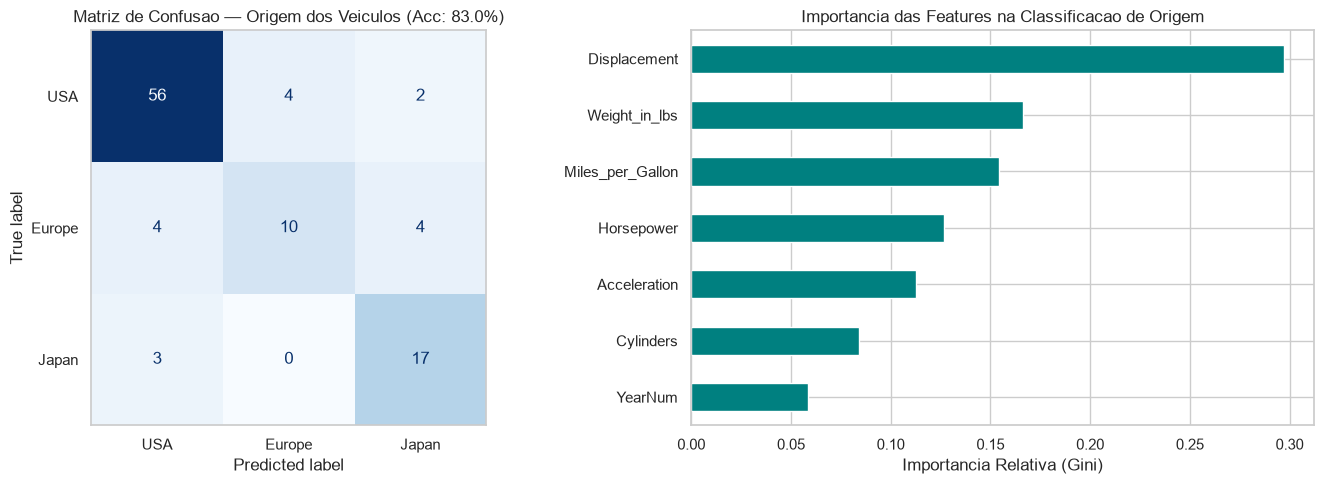

In [50]:
cars_df = load_and_prepare_cars()
print(f"Dimensoes do dataset cars limpo: {cars_df.shape}")
print("Distribuicao por regiao de origem:")
display(cars_df["Origin"].value_counts().rename("quantidade").to_frame())
display(cars_df.head())

CAR_CLASS_FEATURES = [
    "Miles_per_Gallon",
    "Cylinders",
    "Displacement",
    "Horsepower",
    "Weight_in_lbs",
    "Acceleration",
    "YearNum",
]
X_cars_cls = cars_df[CAR_CLASS_FEATURES]
y_cars_cls = cars_df["Origin"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cars_cls, y_cars_cls, test_size=0.25, stratify=y_cars_cls, random_state=RANDOM_STATE
)

rf_cars_cls = RandomForestClassifier(
    n_estimators=300, max_depth=10, random_state=RANDOM_STATE
)
rf_cars_cls.fit(Xc_train, yc_train)
yc_pred = rf_cars_cls.predict(Xc_test)

cls_acc = accuracy_score(yc_test, yc_pred)
print(f"Acuracia do RandomForestClassifier no dataset cars (Origin): {cls_acc:.4f}\n")
print("Relatorio de Classificacao por Origem:")
print(classification_report(yc_test, yc_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_cars = confusion_matrix(yc_test, yc_pred, labels=["USA", "Europe", "Japan"])
ConfusionMatrixDisplay(cm_cars, display_labels=["USA", "Europe", "Japan"]).plot(
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title(f"Matriz de Confusao — Origem dos Veiculos (Acc: {cls_acc:.1%})")
axes[0].grid(False)

car_imp = pd.Series(rf_cars_cls.feature_importances_, index=CAR_CLASS_FEATURES).sort_values()
car_imp.plot(kind="barh", color="teal", ax=axes[1])
axes[1].set_xlabel("Importancia Relativa (Gini)")
axes[1].set_title("Importancia das Features na Classificacao de Origem")

plt.tight_layout()
plt.savefig(FIGURES / "vega_cars_classificacao.png", dpi=160, bbox_inches="tight")
plt.show()

**Análise do Item 5:** A cilindrada (`Displacement`) e o peso (`Weight_in_lbs`) são os atributos mais discriminativos: carros norte-americanos da década de 1970 possuíam motores V6/V8 de grande deslocamento e chassi pesado, enquanto modelos japoneses e europeus concentravam-se em motores compactos de 4 cilindros e menor massa.

---

### 7. Experimentar regressão com Random Forest (`RandomForestRegressor`)

Além da classificação, o Random Forest resolve problemas de **regressão** (onde a saída é um valor numérico contínuo e a predição final é a **média** das estimativas das árvores individuais). Utilizamos `RandomForestRegressor` sobre o dataset `cars` para prever a eficiência energética do veículo em milhas por galão (**`Miles_per_Gallon`**) com base em peso, potência, cilindrada, cilindros, aceleração, ano de fabricação e região de origem.

In [51]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold

CAR_REG_FEATURES = [
    "Cylinders",
    "Displacement",
    "Horsepower",
    "Weight_in_lbs",
    "Acceleration",
    "YearNum",
    "OriginCode",
]
X_cars_reg = cars_df[CAR_REG_FEATURES]
y_cars_reg = cars_df["Miles_per_Gallon"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_cars_reg, y_cars_reg, test_size=0.25, random_state=RANDOM_STATE
)

rf_cars_reg = RandomForestRegressor(
    n_estimators=300, max_depth=10, min_samples_leaf=2, random_state=RANDOM_STATE
)
rf_cars_reg.fit(Xr_train, yr_train)
yr_pred = rf_cars_reg.predict(Xr_test)

# Validacao cruzada em 5 pastas para avaliacao robusta
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
yr_cv_pred = cross_val_predict(rf_cars_reg, X_cars_reg, y_cars_reg, cv=kf)

reg_metrics = pd.DataFrame([
    {
        "Avaliacao": "Holdout Teste (25%)",
        "R2": r2_score(yr_test, yr_pred),
        "RMSE (MPG)": mean_squared_error(yr_test, yr_pred) ** 0.5,
        "MAE (MPG)": mean_absolute_error(yr_test, yr_pred),
    },
    {
        "Avaliacao": "Validacao Cruzada (5-Fold)",
        "R2": r2_score(y_cars_reg, yr_cv_pred),
        "RMSE (MPG)": mean_squared_error(y_cars_reg, yr_cv_pred) ** 0.5,
        "MAE (MPG)": mean_absolute_error(y_cars_reg, yr_cv_pred),
    },
])
display(reg_metrics.round(4))

,Avaliacao,R2,RMSE (MPG),MAE (MPG)
0,Holdout Teste (25%),0.8994,2.3905,1.6779
1,Validacao Cruzada (5-Fold),0.8678,2.8386,1.9625


### 8. Elaborar visualizações

Construímos um painel diagnóstico triplo para a regressão e a exploração multivariada do dataset `cars`:
1. **Relação não linear entre Peso (`Weight_in_lbs`) e Consumo (`Miles_per_Gallon`)** estratificada por região de origem.
2. **Valores Observados vs. Valores Previstos** pelo `RandomForestRegressor` em validação cruzada.
3. **Análise de Resíduos e Importância das Variáveis** na predição do consumo.

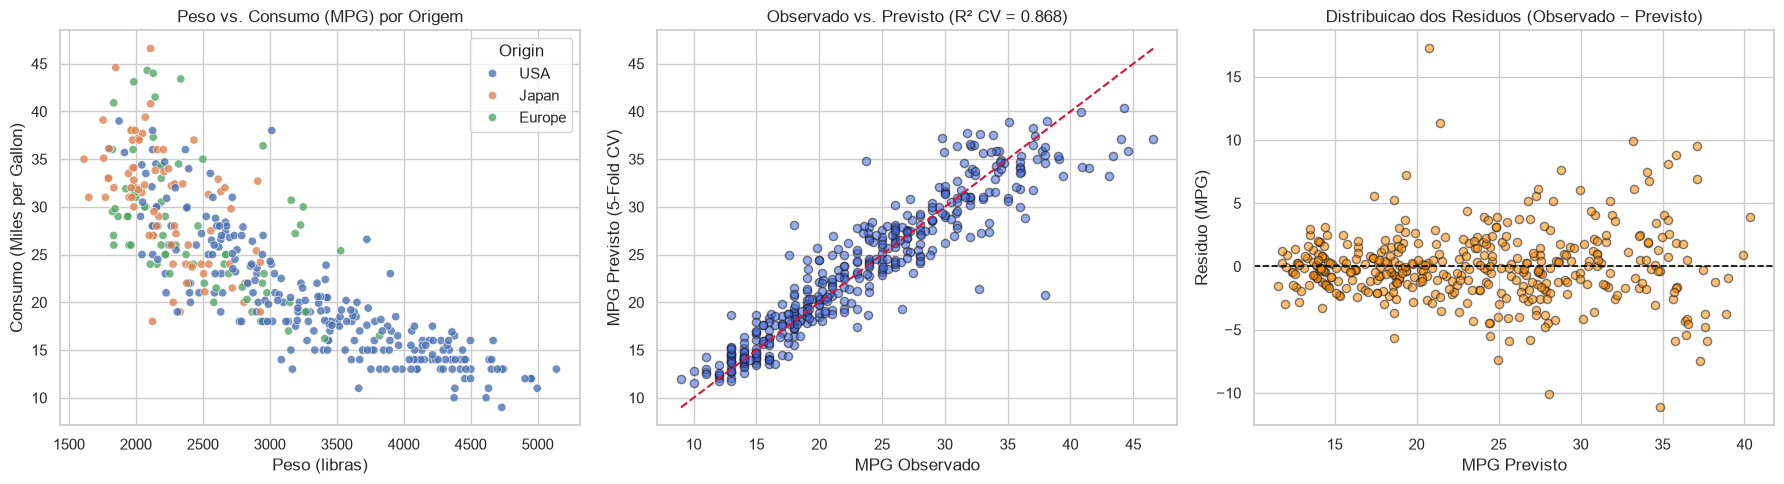

In [52]:
residuals = y_cars_reg - yr_cv_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=cars_df,
    x="Weight_in_lbs",
    y="Miles_per_Gallon",
    hue="Origin",
    alpha=0.8,
    ax=axes[0],
)
axes[0].set_title("Peso vs. Consumo (MPG) por Origem")
axes[0].set_xlabel("Peso (libras)")
axes[0].set_ylabel("Consumo (Miles per Gallon)")

axes[1].scatter(y_cars_reg, yr_cv_pred, alpha=0.55, color="royalblue", edgecolor="k", s=35)
lims = [min(y_cars_reg.min(), yr_cv_pred.min()), max(y_cars_reg.max(), yr_cv_pred.max())]
axes[1].plot(lims, lims, "--", color="crimson", linewidth=1.5)
axes[1].set_title(f"Observado vs. Previsto (R² CV = {r2_score(y_cars_reg, yr_cv_pred):.3f})")
axes[1].set_xlabel("MPG Observado")
axes[1].set_ylabel("MPG Previsto (5-Fold CV)")

axes[2].scatter(yr_cv_pred, residuals, alpha=0.55, color="darkorange", edgecolor="k", s=35)
axes[2].axhline(0, linestyle="--", color="black", linewidth=1.2)
axes[2].set_title("Distribuicao dos Residuos (Observado − Previsto)")
axes[2].set_xlabel("MPG Previsto")
axes[2].set_ylabel("Residuo (MPG)")

plt.tight_layout()
plt.savefig(FIGURES / "vega_cars_regressao.png", dpi=160, bbox_inches="tight")
plt.show()